# **Exploratory Data Analysis with Python - Day 3**

## **Data Manipulation**

### ***Common data quality issues***

1. Missing values
2. Duplicated data
3. Inconsistent data
4. Outliers
5. Irrelevant data
6. Outdated data
7. Data illiteracy


In dealing with data quality issues, we need to:
- First, ask yourself the question: Is it valid? Is there any business rule that allows such instance? Or is this just purely human error?
- Try to understand and identify where the error comes from (during data collecting, source data, transformation steps, ...?)
- Ask yourself the question: What will happen if you keep the ugly data in there? Is it better if you ignore or remove them?
- Ask yourself the question: Is there any way to fix it?
- Make the decision

In [0]:
import pandas as pd

products = pd.read_csv('/Volumes/python/datasets/datasets/olist_products_dataset.csv.zip')
reviews = pd.read_csv('/Volumes/python/datasets/datasets/olist_order_reviews_dataset.csv.zip')

In [0]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [0]:
!pip install duckdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.3/19.3 MB 150.4 MB/s eta 0:00:00
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import duckdb 

duckdb.sql("SELECT review_id, COUNT(DISTINCT order_id) FROM reviews GROUP BY review_id HAVING COUNT(DISTINCT order_id) > 1").show()

┌──────────────────────────────────┬──────────────────────────┐
│            review_id             │ count(DISTINCT order_id) │
│             varchar              │          int64           │
├──────────────────────────────────┼──────────────────────────┤
│ 28642ce6250b94cc72bc85960aec6c62 │                        2 │
│ a0a641414ff718ca079b3967ef5c2495 │                        2 │
│ d433c252647c51309432ca0b763f969b │                        2 │
│ 6ec93e77f444e0b1703740a69122e35d │                        2 │
│ 3242cc306a9218d0377831e175d62fbf │                        2 │
│ 03a6a25db577d0689440933055111897 │                        2 │
│ 7f7241edd813156265f1fc98b45c1a34 │                        2 │
│ 54daab04440b00f318d2c9a0854aafc0 │                        2 │
│ f655b6e860fd2fca8dc258549c5d2a7c │                        2 │
│ 4994fe478b3f3ebda4db5988f417b6a4 │                        2 │
│                ·                 │                        · │
│                ·                 │    

In [0]:
reviews[reviews.order_id == '1c308eca3f339414a92e518e2a2e5ee9']

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
498,505a882ba08a689682a4afc6eb4e5965,1c308eca3f339414a92e518e2a2e5ee9,2,NaN,NaN,2017-12-28 00:00:00,2017-12-31 20:25:02
38850,7fde6a6520102a25fd5ab7728bafbc9b,1c308eca3f339414a92e518e2a2e5ee9,1,NaN,"Até o momento nao recebi o meu produto, fala q...",2017-12-31 00:00:00,2017-12-31 20:19:14


In [0]:
reviews[reviews.review_id == '28642ce6250b94cc72bc85960aec6c62']

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
200,28642ce6250b94cc72bc85960aec6c62,e239d280236cdd3c40cb2c033f681d1c,5,NaN,NaN,2018-03-25 00:00:00,2018-03-25 21:03:02
58385,28642ce6250b94cc72bc85960aec6c62,bc42a955f289870d5789e6e437206300,5,NaN,NaN,2018-03-25 00:00:00,2018-03-25 21:03:02


In [0]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [0]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [0]:
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [0]:
reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [0]:
products[products.isnull().any(axis = 1)]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
...,...,...,...,...,...,...,...,...,...
32515,b0a0c5dd78e644373b199380612c350a,NaN,NaN,NaN,NaN,1800.0,30.0,20.0,70.0
32589,10dbe0fbaa2c505123c17fdc34a63c56,NaN,NaN,NaN,NaN,800.0,30.0,10.0,23.0
32616,bd2ada37b58ae94cc838b9c0569fecd8,NaN,NaN,NaN,NaN,200.0,21.0,8.0,16.0
32772,fa51e914046aab32764c41356b9d4ea4,NaN,NaN,NaN,NaN,1300.0,45.0,16.0,45.0


In [0]:
products['product_weight_g'].isnull()

,product_weight_g
0,False
1,False
2,False
3,False
4,False
...,...
32946,False
32947,False
32948,False
32949,False


In [0]:
products[products['product_height_cm'].isnull()]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [0]:
products[['product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g']].isnull().all(axis=1).sum()

np.int64(1)

In [0]:
products[products[['product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty']].isnull().all(axis = 1)]

In [0]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='object')

In [0]:
products['product_category_name'] == 'bebes'

,product_category_name
0,False
1,False
2,False
3,True
4,False
...,...
32946,False
32947,False
32948,False
32949,False


In [0]:
bebes = products[products['product_category_name'] == 'bebes']

In [0]:
bebes.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 919 entries, 3 to 32941
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  919 non-null    object 
 1   product_category_name       919 non-null    object 
 2   product_name_lenght         919 non-null    float64
 3   product_description_lenght  919 non-null    float64
 4   product_photos_qty          919 non-null    float64
 5   product_weight_g            918 non-null    float64
 6   product_length_cm           918 non-null    float64
 7   product_height_cm           918 non-null    float64
 8   product_width_cm            918 non-null    float64
dtypes: float64(7), object(2)
memory usage: 71.8+ KB


In [0]:
bebes[bebes['product_weight_g'].isnull()]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN


In [0]:
bebes[bebes.isnull().any(axis = 1)]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN


In [0]:
bebes.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,919.000000,919.000000,919.000000,918.000000,918.000000,918.000000,918.000000
mean,46.056583,824.261153,2.352557,3655.201525,37.147059,21.617647,28.717865
std,11.382298,544.414530,1.735121,5665.129577,17.945730,16.591138,13.964589
min,7.000000,4.000000,1.000000,50.000000,14.000000,2.000000,8.000000
25%,38.000000,381.000000,1.000000,400.000000,23.000000,10.000000,16.000000
50%,49.000000,728.000000,2.000000,850.000000,33.000000,16.000000,25.000000
75%,55.500000,1133.000000,3.000000,5106.250000,45.000000,30.000000,40.000000
max,64.000000,3923.000000,19.000000,30000.000000,102.000000,97.000000,84.000000


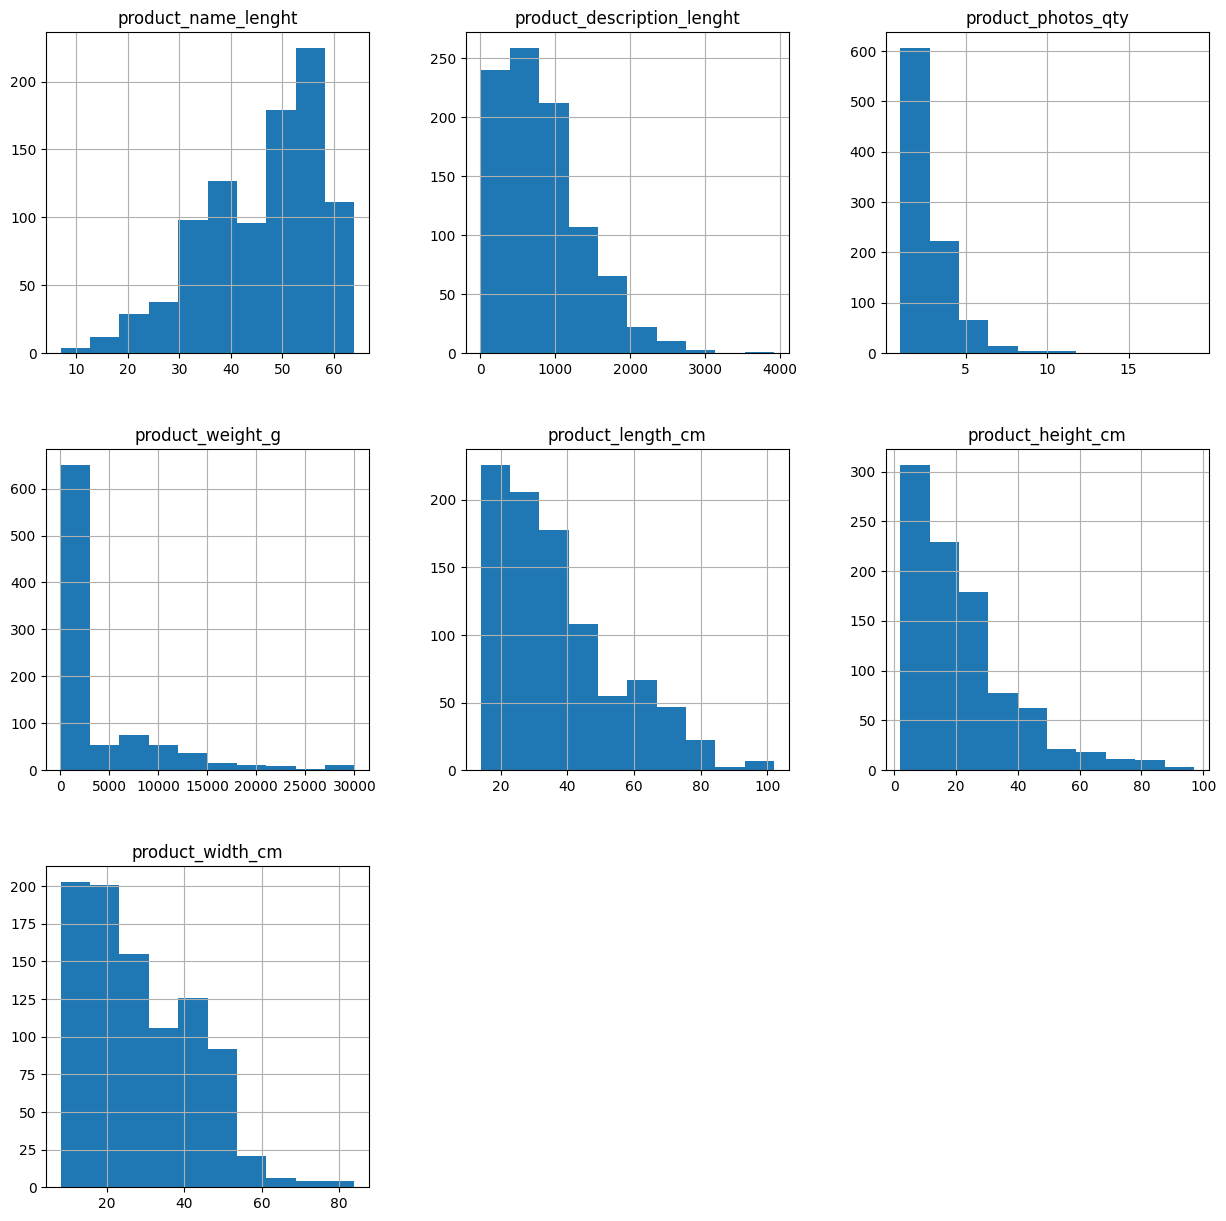

In [0]:
import matplotlib.pyplot as plt

bebes.hist(figsize=(15,15))
plt.show()

In [0]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [0]:
products.product_description_lenght.median()

595.0

In [0]:
bebes.product_description_lenght.median()

728.0

In [0]:
bebes_med_weight = bebes['product_weight_g'].median()

In [0]:
bebes_med_weight

850.0

In [0]:
bebes['product_weight_g'].fillna(10)

In [0]:
#bebes_weight_med = bebes['product_weight_g'].median()

bebes['product_weight_g'].fillna(bebes['product_weight_g'].median(), inplace = True)

/home/spark-f0c1917a-1f07-45d2-9114-98/.ipykernel/2932/command-7388631713260364-1232780837:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bebes['product_weight_g'].fillna(bebes['product_weight_g'].median(), inplace = True)


In [0]:
bebes[bebes.isnull().any(axis = 1)]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,850.0,NaN,NaN,NaN


In [0]:
# Fill missing values
products['product_weight_g'].fillna(bebes_med_weight, inplace = True)

# The previous code is equal to

#products['product_weight_g'] = products['product_weight_g'].fillna(bebes_avg_weight)

In [0]:
# Similarly, we can fill in other columns without creating new variables

bebes['product_length_cm'].fillna(bebes['product_length_cm'].median(), inplace = True)
bebes['product_height_cm'].fillna(bebes['product_height_cm'].median(), inplace = True)
bebes['product_width_cm'].fillna(bebes['product_width_cm'].median(), inplace = True)

/home/spark-f0c1917a-1f07-45d2-9114-98/.ipykernel/2932/command-7388631713260367-27071629:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bebes['product_length_cm'].fillna(bebes['product_length_cm'].median(), inplace = True)
/home/spark-f0c1917a-1f07-45d2-9114-98/.ipykernel/2932/command-7388631713260367-27071629:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bebes['product_height_cm'].fillna(bebes['product_height_cm'].median(), inplace = True)
/home/spark-f0c1917a-1f07-45d2-9114-98/.ipykernel/2932/command-7388631713260367-27071629:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Dat

In [0]:
bebes[bebes.product_id == '09ff539a621711667c43eba6a3bd8466']

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,850.0,33.0,16.0,25.0


### ***Boxplot***

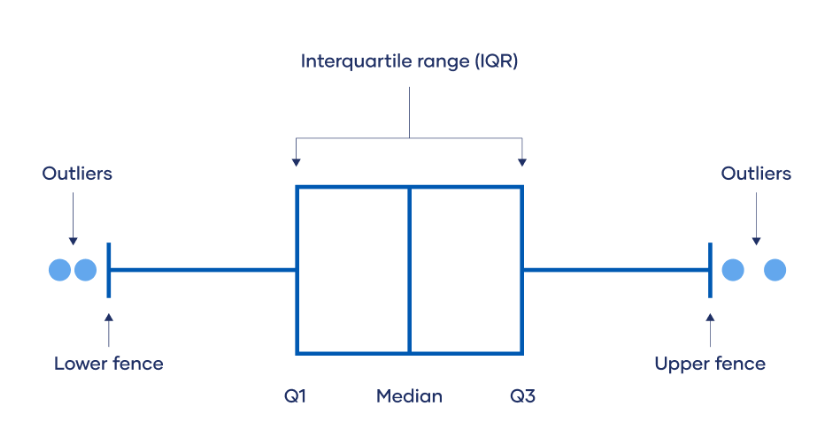

In [0]:
products.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


<Axes: >

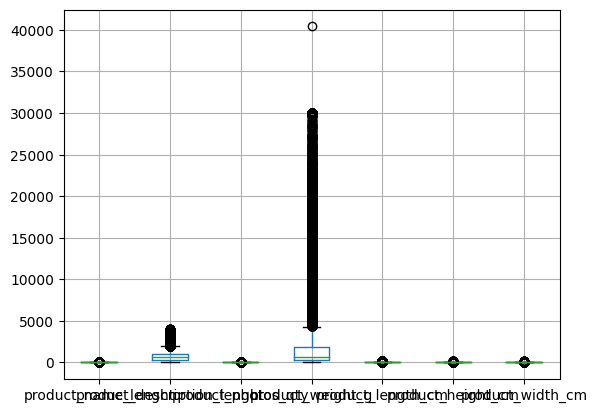

In [0]:
import matplotlib.pyplot as plt

products.boxplot()

<Axes: >

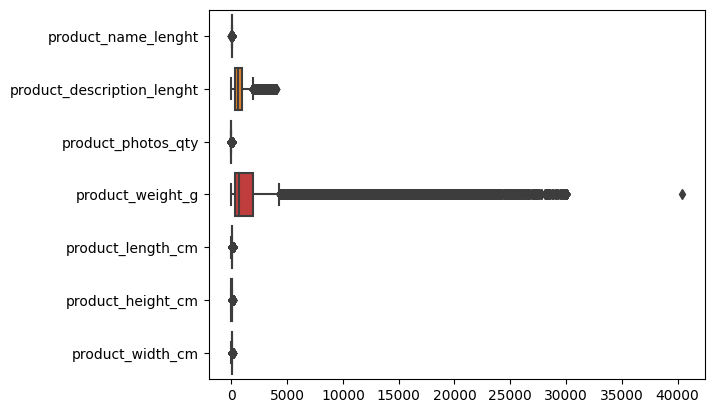

In [0]:
import seaborn as sns

sns.boxplot(data = products, orient = 'h')

<Axes: >

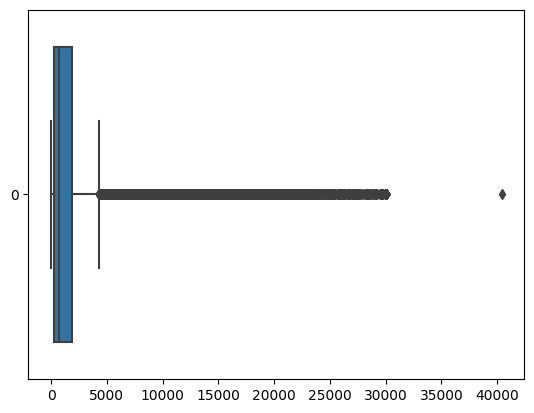

In [0]:
sns.boxplot(data = products['product_weight_g'], orient = 'h')

<Axes: >

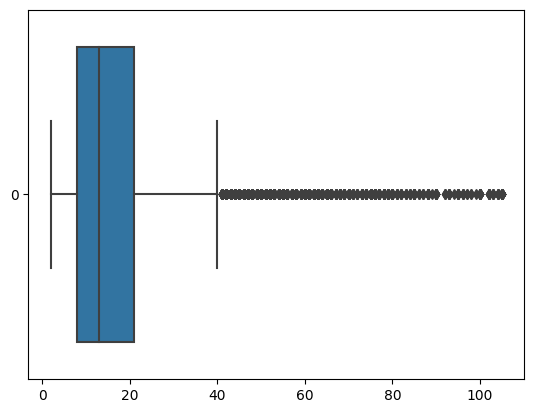

In [0]:
sns.boxplot(data = products['product_height_cm'], orient = 'h')

<Axes: xlabel='product_height_cm', ylabel='product_category_name'>

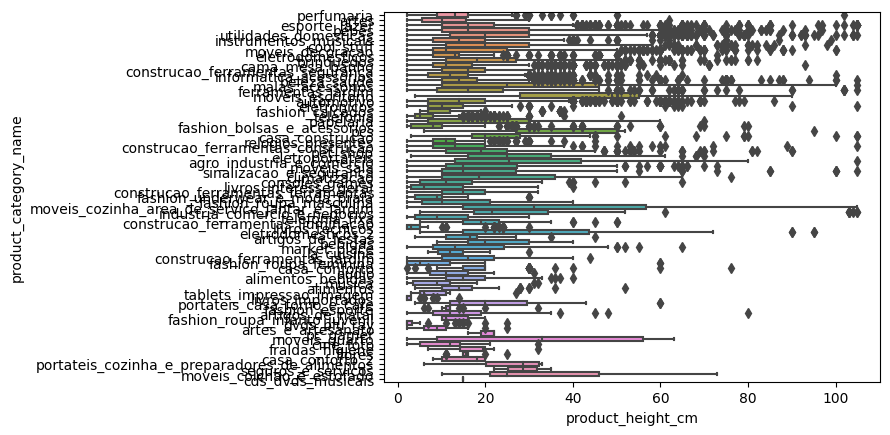

In [0]:
sns.boxplot(data = products, x = 'product_height_cm', y = 'product_category_name', dodge = True)

How to make it look better?

<Axes: xlabel='product_height_cm', ylabel='product_category_name'>

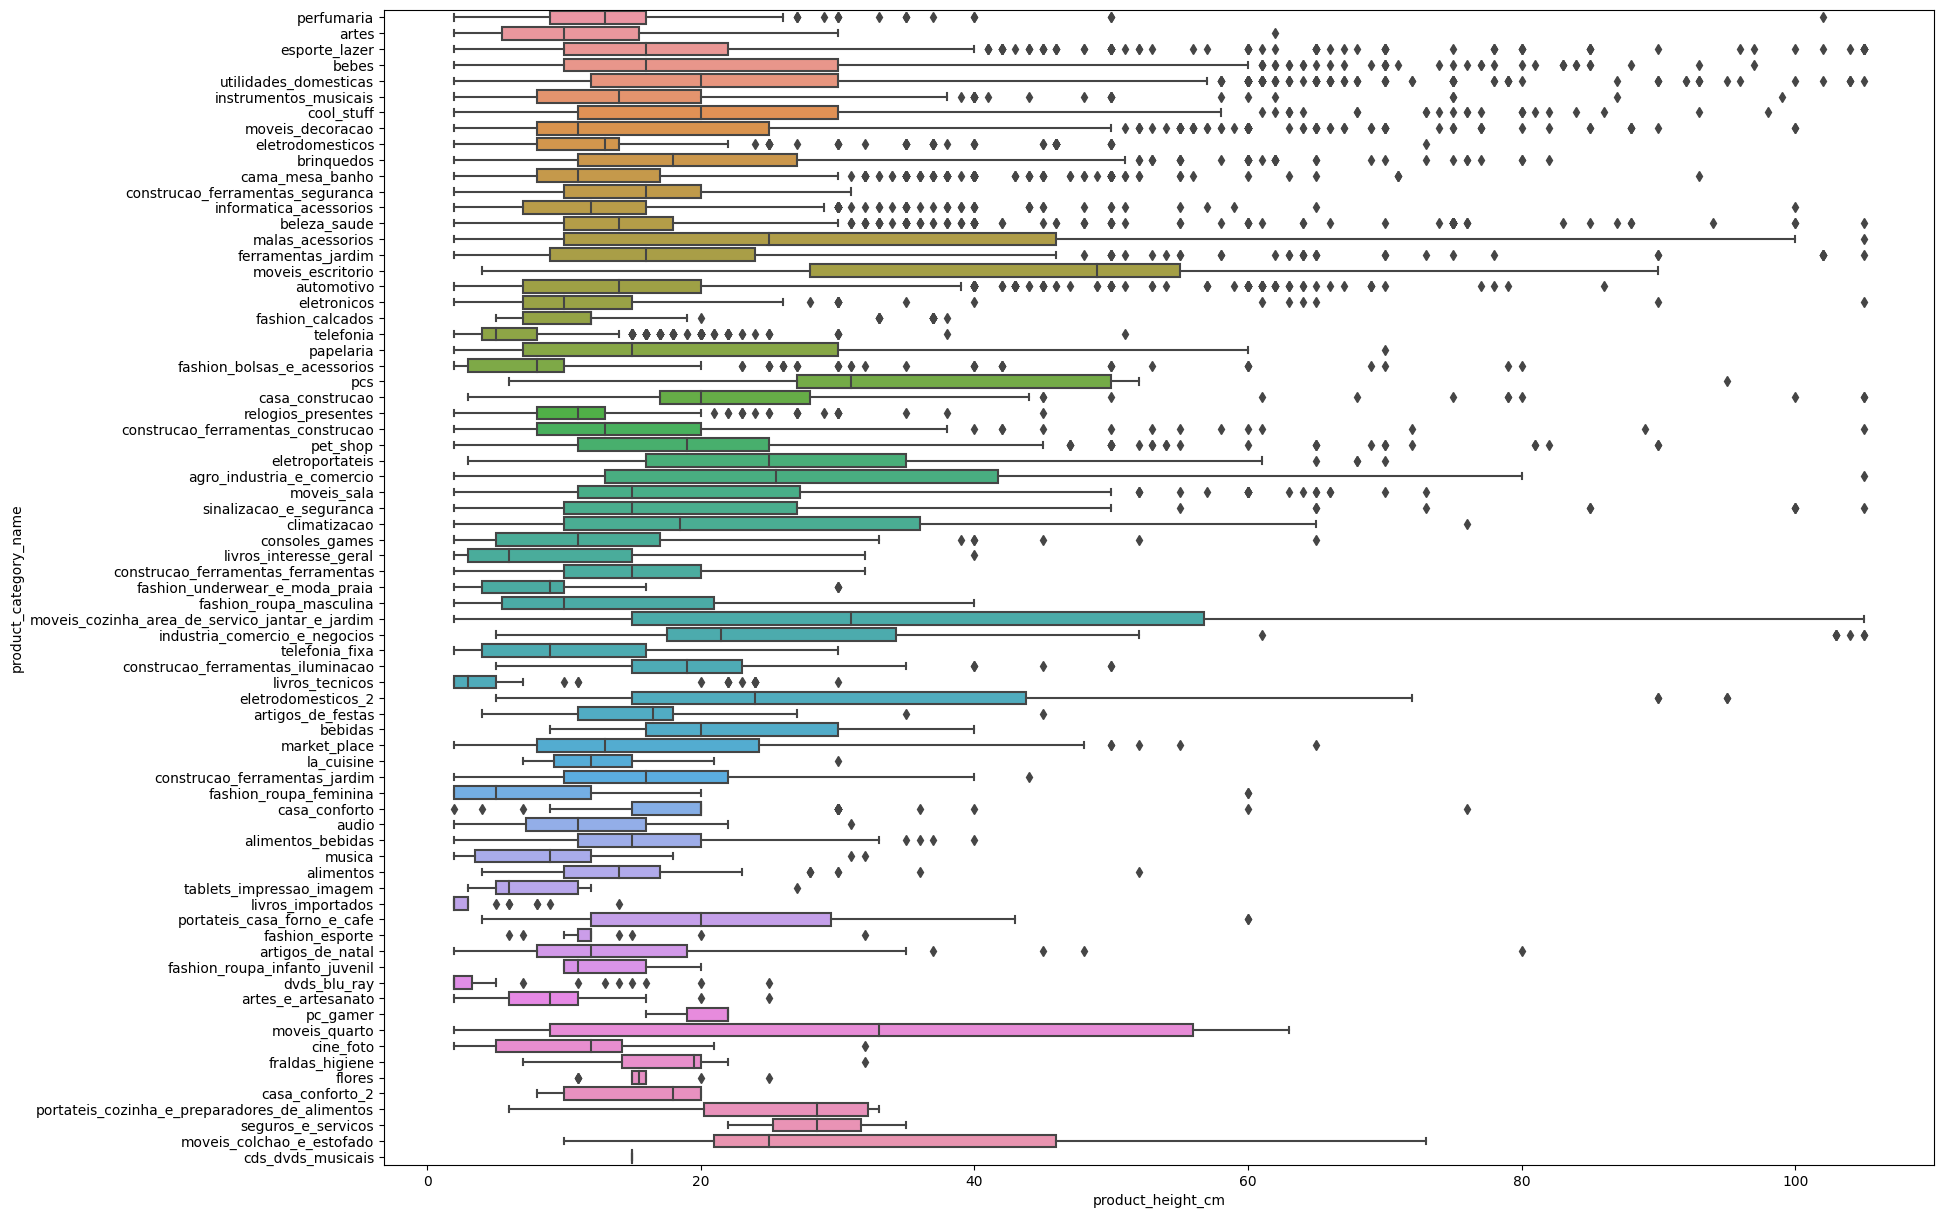

In [0]:
plt.figure(figsize=(20,15))
sns.boxplot(data = products, x = 'product_height_cm', y = 'product_category_name', dodge = True)

### ***Determining Outliers using Interquiartile Range Approach***

IQR = Q3 - Q1

Upper bound = Q3 + 1.5*IQR

Lower bound = Q1 - 1.5*IQR

In [0]:
products['product_height_cm'].quantile(0.5)

13.0

In [0]:
products['product_height_cm'].median()

13.0

In [0]:
# Calculating IQR

IQR = products['product_weight_g'].quantile(0.75) - products['product_weight_g'].quantile(0.25)

#Calculating upper bound
Upper = products['product_weight_g'].quantile(0.75) + 1.5*IQR

#Calculating lower bound
Lower = products['product_weight_g'].quantile(0.25) - 1.5*IQR

In [0]:
print('IQR =', IQR, '\nUpper bound =', Upper, '\nLower bound =', Lower)

IQR = 1600.0 
Upper bound = 4300.0 
Lower bound = -2100.0


<Axes: >

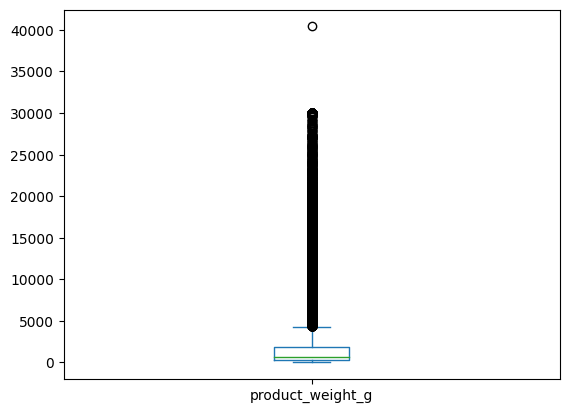

In [0]:
products['product_weight_g'].plot.box()

> We can see that the lower bound is now `-11.5`, which is invalid. Therefore, any value above the upper bound of `40.5` will be considered as outliers for `product_height_cm`

***Challenge***:

1. How can you get the IQR for all numerical columns in one go?
2. How can you calculate lower bound and upper bound for each numerical column efficiently using the result from the first challenge?

In [0]:
!python3 --version

Python 3.11.10


In [0]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='object')

In [0]:
products.quantile(0.5)

/home/spark-f0c1917a-1f07-45d2-9114-98/.ipykernel/2932/command-4736804258926029-4290734427:1: FutureWarning: The default value of numeric_only in DataFrame.quantile is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  products.quantile(0.5)


product_name_lenght            51.0
product_description_lenght    595.0
product_photos_qty              1.0
product_weight_g              700.0
product_length_cm              25.0
product_height_cm              13.0
product_width_cm               20.0
Name: 0.5, dtype: float64

In [0]:
temp = products[['product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm']]


In [0]:
temp.quantile(0.75)

product_name_lenght             57.0
product_description_lenght     972.0
product_photos_qty               3.0
product_weight_g              1900.0
product_length_cm               38.0
product_height_cm               21.0
product_width_cm                30.0
Name: 0.75, dtype: float64

In [0]:
products.quantile(0.75) - products.quantile(0.25)

/home/spark-f0c1917a-1f07-45d2-9114-98/.ipykernel/2932/command-5450702069523946-2193622698:1: FutureWarning: The default value of numeric_only in DataFrame.quantile is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  products.quantile(0.75) - products.quantile(0.25)


product_name_lenght             15.0
product_description_lenght     633.0
product_photos_qty               2.0
product_weight_g              1600.0
product_length_cm               20.0
product_height_cm               13.0
product_width_cm                15.0
dtype: float64

In [0]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [0]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='object')

In [0]:
products[['product_name_lenght',
       'product_description_lenght']].quantile(0.25)

,0.25
product_name_lenght,42.0
product_description_lenght,339.0


In [0]:
num_cols = ['product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm']


IQR = products[num_cols].quantile(0.75) - products[num_cols].quantile(0.25)

#Calculating upper bound
Upper = products[num_cols].quantile(0.75) + 1.5*IQR

#Calculating lower bound
Lower = products[num_cols].quantile(0.25) - 1.5*IQR

In [0]:
IQR

product_name_lenght             15.0
product_description_lenght     633.0
product_photos_qty               2.0
product_weight_g              1600.0
product_length_cm               20.0
product_height_cm               13.0
product_width_cm                15.0
dtype: float64

In [0]:
Upper

product_name_lenght             79.5
product_description_lenght    1921.5
product_photos_qty               6.0
product_weight_g              4300.0
product_length_cm               68.0
product_height_cm               40.5
product_width_cm                52.5
dtype: float64

In [0]:
Lower

product_name_lenght             19.5
product_description_lenght    -610.5
product_photos_qty              -2.0
product_weight_g             -2100.0
product_length_cm              -12.0
product_height_cm              -11.5
product_width_cm                -7.5
dtype: float64

### ***Feature Scaling***

In [0]:
products.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


> Look at the statistics of the data, can you spot the difference?

1. Normalisation:
Normalization is a scaling technique in which values are shifted and rescaled so that they end up ranging between 0 and 1. It is also known as Min-Max scaling.

Formula: 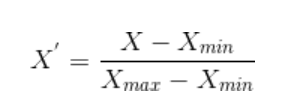



2. Standardisation: Standardization is another scaling method where the values are centered around the mean with a unit standard deviation. This means that the mean of the attribute becomes zero, and the resultant distribution has a unit standard deviation.

Formula: 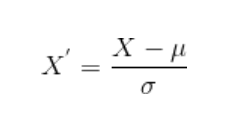

In [0]:
products['product_weight_g'].std()

4282.038730977634

In [0]:
products['product_weight_g'].mean()

np.float64(2276.4724877841513)

In [0]:
products['product_weight_g'] 

0          225.0
1         1000.0
2          154.0
3          371.0
4          625.0
          ...   
32946    12300.0
32947     1700.0
32948     1400.0
32949      700.0
32950     2083.0
Name: product_weight_g, Length: 32951, dtype: float64

In [0]:
(products['product_weight_g'] - products['product_weight_g'].mean()) / products['product_weight_g'].std()

0       -0.479088
1       -0.298099
2       -0.495669
3       -0.444992
4       -0.385674
           ...   
32946    2.340831
32947   -0.134626
32948   -0.204686
32949   -0.368159
32950   -0.045182
Name: product_weight_g, Length: 32951, dtype: float64

In [0]:
products['product_weight_g'].max()

40425.0

In [0]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='object')

In [0]:
weight_min = products['product_weight_g'].min()
weight_max = products['product_weight_g'].max()
products['scaled_weight'] = (products['product_weight_g'] - weight_min) / (weight_max - weight_min)

In [0]:
products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'scaled_weight'],
      dtype='object')

In [0]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,scaled_weight
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,0.005566
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,0.024737
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,0.003810
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,0.009177
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,0.015461


In [0]:
products[['product_weight_g', 'scaled_weight']]

,product_weight_g,scaled_weight
0,225.0,0.005566
1,1000.0,0.024737
2,154.0,0.003810
3,371.0,0.009177
4,625.0,0.015461
...,...,...
32946,12300.0,0.304267
32947,1700.0,0.042053
32948,1400.0,0.034632
32949,700.0,0.017316


In [0]:
products['standard_scaled_weight'] = (products.product_weight_g - products.product_weight_g.mean()) / products.product_weight_g.std()

In [0]:
products[['product_weight_g', 'scaled_weight', 'standard_scaled_weight']]

,product_weight_g,scaled_weight,standard_scaled_weight
0,225.0,0.005566,-0.479088
1,1000.0,0.024737,-0.298099
2,154.0,0.003810,-0.495669
3,371.0,0.009177,-0.444992
4,625.0,0.015461,-0.385674
...,...,...,...
32946,12300.0,0.304267,2.340831
32947,1700.0,0.042053,-0.134626
32948,1400.0,0.034632,-0.204686
32949,700.0,0.017316,-0.368159


array([[<Axes: title={'center': 'product_weight_g'}>,
        <Axes: title={'center': 'scaled_weight'}>],
       [<Axes: title={'center': 'standard_scaled_weight'}>, <Axes: >]],
      dtype=object)

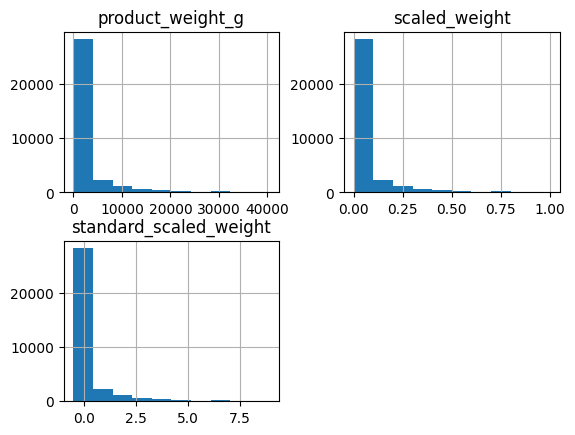

In [0]:
products[['product_weight_g', 'scaled_weight', 'standard_scaled_weight']].hist()

> What if there are multiple columns that need to be rescaled? Which solution can be used for better reusability?

### ***Function in Python***

In [0]:
UDF - User defined function

In [0]:
products.head(9)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,scaled_weight,standard_scaled_weight
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,0.005566,-0.479088
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,0.024737,-0.298099
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,0.003810,-0.495669
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,0.009177,-0.444992
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,0.015461,-0.385674
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,60.0,745.0,1.0,200.0,38.0,5.0,11.0,0.004947,-0.484926
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,56.0,1272.0,4.0,18350.0,70.0,24.0,44.0,0.453927,3.753709
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,56.0,184.0,2.0,900.0,40.0,8.0,40.0,0.022263,-0.321453
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,57.0,163.0,1.0,400.0,27.0,13.0,17.0,0.009895,-0.438219


In python, user-built function can be created with the following systax:
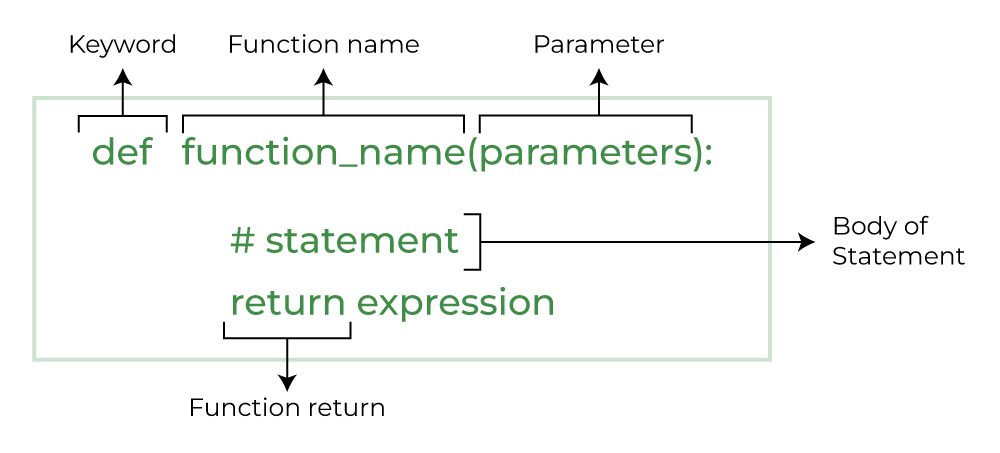

In [0]:
reviews.head(n = 7)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53
5,15197aa66ff4d0650b5434f1b46cda19,b18dcdf73be66366873cd26c5724d1dc,1,NaN,NaN,2018-04-13 00:00:00,2018-04-16 00:39:37
6,07f9bee5d1b850860defd761afa7ff16,e48aa0d2dcec3a2e87348811bcfdf22b,5,NaN,NaN,2017-07-16 00:00:00,2017-07-18 19:30:34


In [0]:
def add_2_numbers(a, b = 1):
    return a + b

In [0]:
add_2_numbers(5,7)

12

User input: opening balance

Fixed rate: 5.5%

Return:
- Opening balance is
- Interest is
- Closing balance is

In [0]:
def interest_calc(bal):
   interest = bal*5.5/100
   final_bal = bal + interest
   return  bal, interest, final_bal

In [0]:
outp = interest_calc(10000000)
print('Balance is', outp[0])
print('Interest is', outp[1])
print('Final balance is', outp[2])

Balance is 10000000
Interest is 550000.0
Final balance is 10550000.0


In [0]:
weight_min = products['product_weight_g'].min()
weight_max = products['product_weight_g'].max()
products['scaled_weight'] = (products['product_weight_g'] - weight_min) / (weight_max - weight_min)

In [0]:
def normalise(col):
    return (col - col.min()) / (col.max() - col.min())

In [0]:
lst = [5, 7, 8]

In [0]:
lst - 1

---------------------------------------------------------------------------
TypeError                                 Traceback (most recent call last)
File <command-6757074649417192>, line 1
----> 1 lst - 1

TypeError: unsupported operand type(s) for -: 'list' and 'int'

In [0]:
normalise(products['product_height_cm'])

0        0.077670
1        0.155340
2        0.067961
3        0.019417
4        0.145631
           ...   
32946    0.368932
32947    0.165049
32948    0.048544
32949    0.106796
32950    0.000000
Name: product_height_cm, Length: 32951, dtype: float64

In [0]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [0]:
products['width_norm'] = normalise(products['product_width_cm'])

In [0]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,width_norm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,0.071429
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,0.125000
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,0.080357
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,0.178571
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,0.062500


In [0]:
min(products.product_height_cm)

2.0

In [0]:
def calc_interest(bal = 2000):
    return bal*0.05

In [0]:
def calc_interest(bal, interest_rate=0.05):
    return bal*interest_rate

In [0]:
calc_interest(5000)

250.0

In [0]:
calc_interest(5000)

250.0

In [0]:
intr = calc_interest(300)

In [0]:
intr

In [0]:
def add_2_numbers(a, b):
  c = a + b
  return c

In [0]:
total = add_2_numbers(2,3)

total = total + 1

In [0]:
total

6

In [0]:
def add_2_numbers(b = 3, a = 2):
  c = a + b
  return c

In [0]:
add_2_numbers()

5

In [0]:
add_2_numbers(6,8)

14

In [0]:
def add_2_numbers():
  a = 2
  b = 3
  c = a + b
  return b

In [0]:
add_2_numbers()

3

In [0]:
def c_to_f(a = 0):
  return (a*1.8) + 32

In [0]:
c_to_f(30)

86.0

In [0]:
# Example 1:
# Function to calculate age, given the year was born

def calculate_age(year = 2026):
  age = 2025 - year
  return age

# Calling the function

print('I was born in 1999, so my age is', calculate_age(1999))

I was born in 1999, so my age is 26


In [0]:
calculate_age(2012)

13

In [0]:
def normalise_column(col):
    return (col - col.min()) / (col.max() - col.min())

In [0]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [0]:
normalise_column(products.product_weight_g)

0        0.005566
1        0.024737
2        0.003810
3        0.009177
4        0.015461
           ...   
32946    0.304267
32947    0.042053
32948    0.034632
32949    0.017316
32950    0.051528
Name: product_weight_g, Length: 32951, dtype: float64

In [0]:
def normalise_column(col):
    result = []
    for i in col:
        result.append((i - min(col)) / (max(col) - min(col)))
    return result

In [0]:
lst = [1,2,3,4,5]


# normalise_column(lst)

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-7652541475316168>, line 3
      1 lst = [1,2,3,4,5]
----> 3 avg(lst)

NameError: name 'avg' is not defined

In [0]:
def normalisation(x):
  return (x-x.min()) / (x.max() - x.min())

In [0]:
def standardisation(x):
  return (x - x.mean()) / x.std()

In [0]:
products['normalised_height'] = normalisation(products.product_height_cm)

,product_height_cm
0,0.077670
1,0.155340
2,0.067961
3,0.019417
4,0.145631
...,...
32946,0.368932
32947,0.165049
32948,0.048544
32949,0.106796


In [0]:
def interest_calculator(bal, interest):
  return bal*(1-interest)

In [0]:
interest_calculator(interest = 0.032, bal = 1000)

968.0

In [0]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,scaled_weight,standard_scaled_weight
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,0.005566,-0.479088
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,0.024737,-0.298099
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,0.003810,-0.495669
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,0.009177,-0.444992
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,0.015461,-0.385674


In [0]:
products.head(6)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,scaled_weight,standard_scaled_weight
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,0.005566,-0.479088
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,0.024737,-0.298099
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,0.003810,-0.495669
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,0.009177,-0.444992
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,0.015461,-0.385674
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,60.0,745.0,1.0,200.0,38.0,5.0,11.0,0.004947,-0.484926


> Challenge: if I remove `return` statement, will it throw any error? What does it mean?

> ***Lambda function***

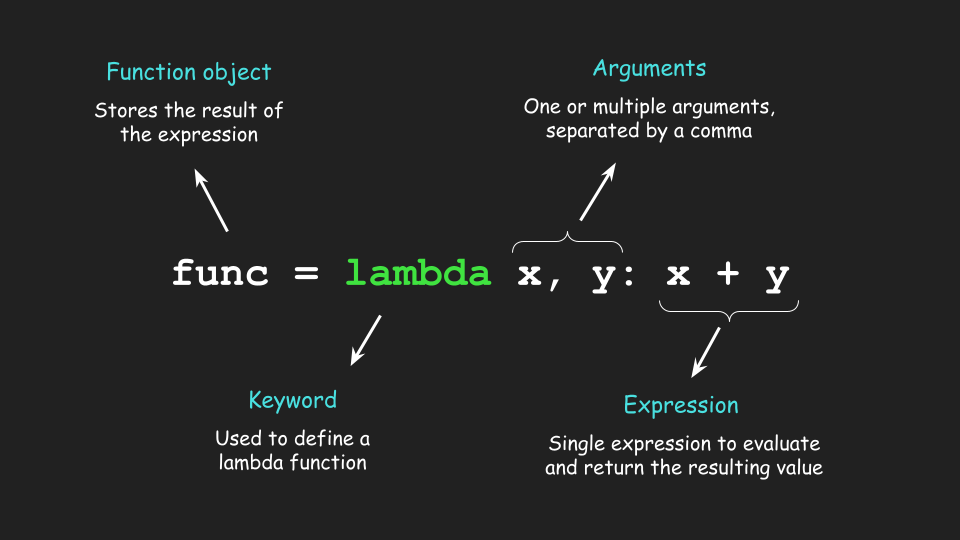

In [0]:
def interest_calc(bal):
   interest = bal*5.5/100
   final_bal = bal + interest
   return  bal, interest, final_bal

In [0]:
intr_calc = lambda bal: bal*5.5/100

In [0]:
intr_calc(10000000)

550000.0

In [0]:
normalise = lambda col: (col - col.min()) / (col.max() - col.min())

In [0]:
normalise_column = lambda col: (col - col.min())/ (col.max() - col.min())

In [0]:
normalise_column(products.product_height_cm)

0        0.077670
1        0.155340
2        0.067961
3        0.019417
4        0.145631
           ...   
32946    0.368932
32947    0.165049
32948    0.048544
32949    0.106796
32950    0.000000
Name: product_height_cm, Length: 32951, dtype: float64

In [0]:
standardisation = lambda x: (x - x.mean()) / x.std()

In [0]:
normalisation = lambda a: (a - a.min()) / (a.max() - a.min())

In [0]:
standardisation(products.product_length_cm)

,product_length_cm
0,-0.875883
1,-0.048188
2,-0.757640
3,-0.284672
4,-0.639398
...,...
32946,0.543022
32947,-0.875883
32948,-0.225551
32949,0.010933


In [0]:
normalisation(products.product_length_cm)

,product_length_cm
0,0.091837
1,0.234694
2,0.112245
3,0.193878
4,0.132653
...,...
32946,0.336735
32947,0.091837
32948,0.204082
32949,0.244898


In [0]:
cal_interest = lambda bal, rate = 0.015: bal * rate

In [0]:
cal_interest(1000)

15.0

In [0]:
import numpy as np

np.log(9)

np.float64(2.1972245773362196)

In [0]:
# Example of lambda function for log normalisation

# The function is used to log transform the column/value

import numpy as np

log_norm = lambda x: np.log(x)

In [0]:
log_norm(1)

np.float64(0.0)

In [0]:
products['product_weight_g'] = products['product_weight_g'].replace(0.0, 0.000000000001)

In [0]:
products['product_weight_g'].min()

1e-12

In [0]:
# Calling function

log_norm(products['product_weight_g'])

/usr/local/lib/python3.11/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,product_weight_g
0,5.416100
1,6.907755
2,5.036953
3,5.916202
4,6.437752
...,...
32946,9.417355
32947,7.438384
32948,7.244228
32949,6.551080


In [0]:
products['log_norm_weight'] = log_norm(products['product_weight_g'])

In [0]:
products[['product_weight_g', 'log_norm_weight']]

,product_weight_g,log_norm_weight
0,225.0,5.416100
1,1000.0,6.907755
2,154.0,5.036953
3,371.0,5.916202
4,625.0,6.437752
...,...,...
32946,12300.0,9.417355
32947,1700.0,7.438384
32948,1400.0,7.244228
32949,700.0,6.551080


array([[<Axes: title={'center': 'product_weight_g'}>,
        <Axes: title={'center': 'log_norm_weight'}>]], dtype=object)

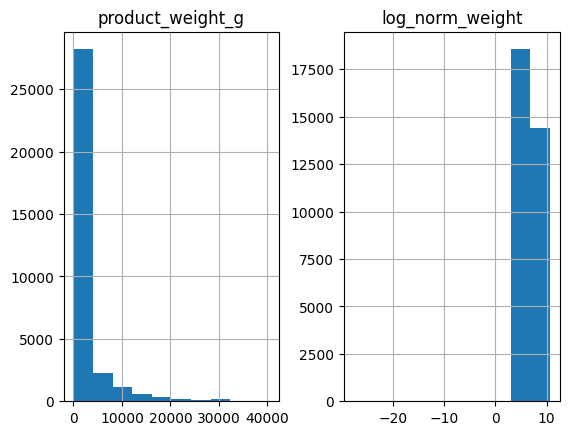

In [0]:
products[['product_weight_g', 'log_norm_weight']].hist()

In [0]:
products.log_norm_weight.min()

-27.631021115928547

<Axes: >

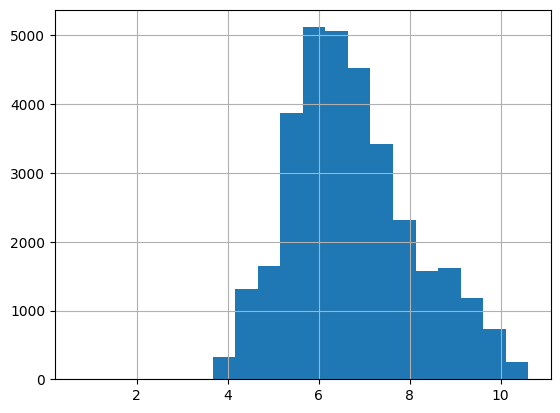

In [0]:
products[products.log_norm_weight > -27.631021115928547]['log_norm_weight'].hist(bins=20)

<Axes: >

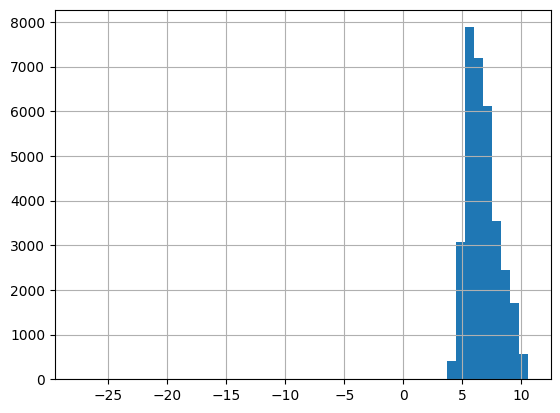

In [0]:
products.log_norm_weight.hist(bins=50)

> Challenge: Convert the previous lambda function in to full-form function.

## **Homework**

Write a (lambda) function to standardise data.
Requirement:

- Input: table, column
- Output: standarded value/array